In [ ]:
import os
import sys
import pandas as pd
import plotly.express as px
import numpy as np
from pathlib import Path
import json
import ast
import matplotlib.pyplot as plt
from datetime import datetime

sys.path.append("..")

# Load and clean data

In [66]:
path = Path(r"..\data\features\features_band_seq1.csv")
df = pd.read_csv(path)
df["sampled_at"] = pd.to_datetime(df["sampled_at"])
df = df.loc[df["sampled_at"] > datetime(2023,1,1)].reset_index(drop=True)
df["rms_per_band"] = df["rms_per_band"].apply(ast.literal_eval)
df = pd.concat((df, pd.json_normalize(df["rms_per_band"])), axis=1)

features = list(df["rms_per_band"].iloc[0].keys())
df = df.sort_values("sampled_at").reset_index(drop=True)

# View data

In [68]:
AXES = ["x", "y", "z"]
CABLES = ["c1", "c2", "c3", "c4"]

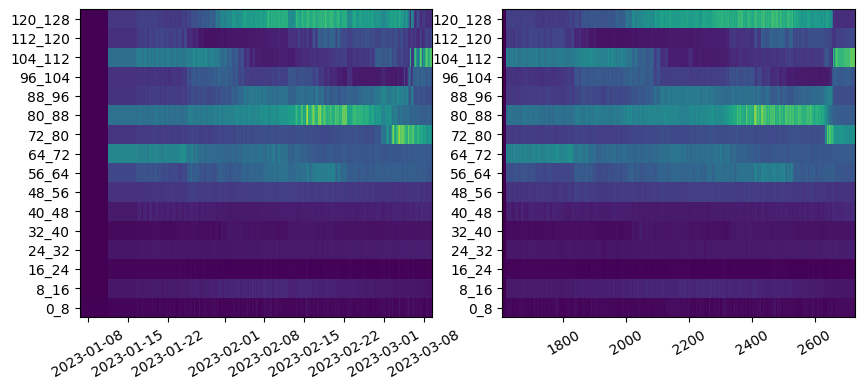

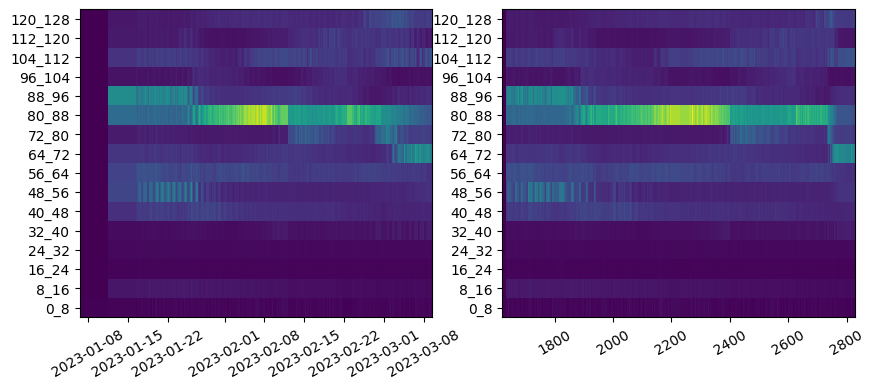

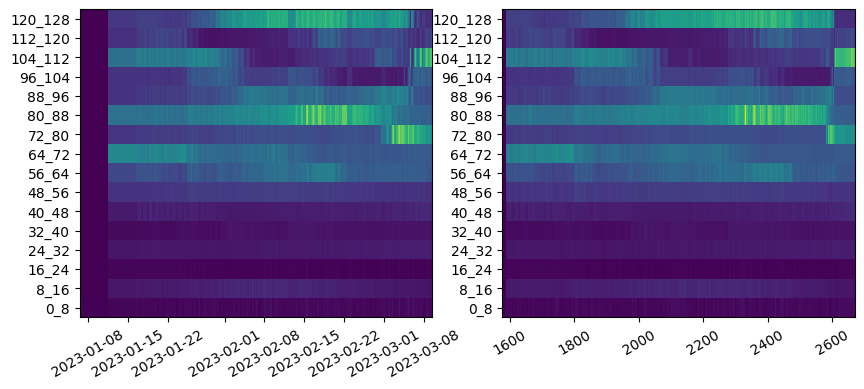

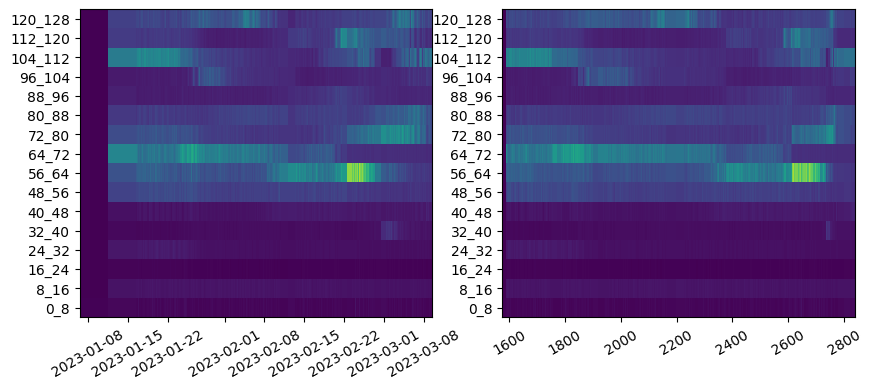

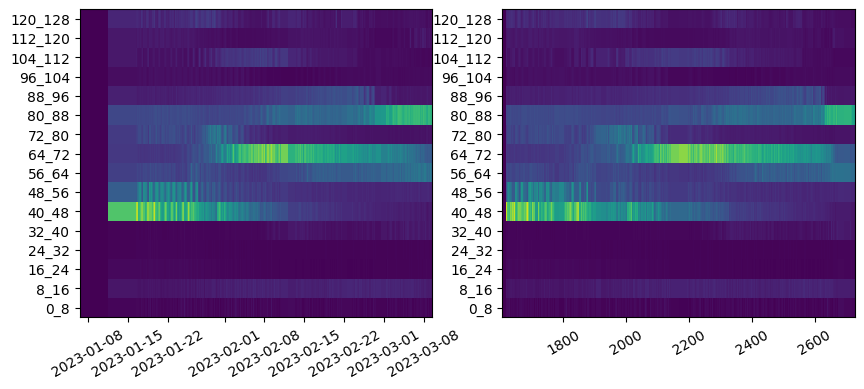

...

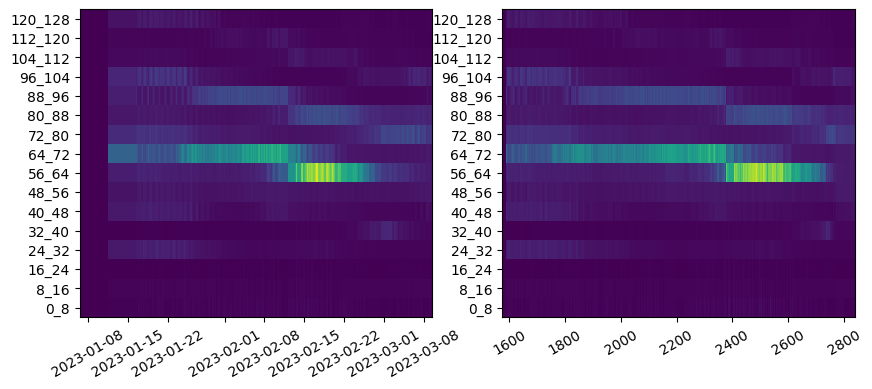

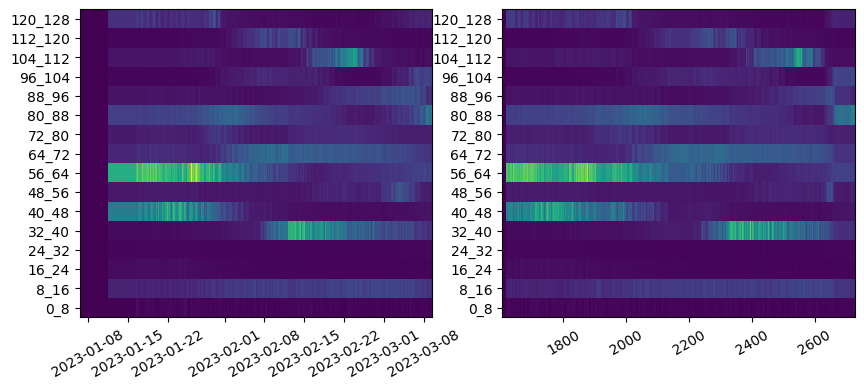

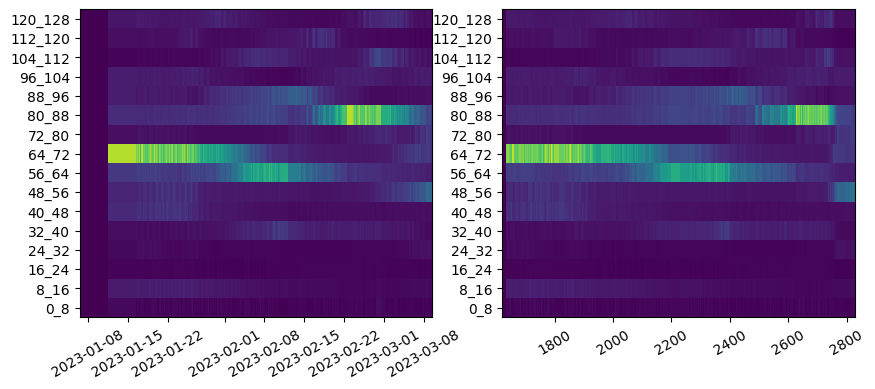

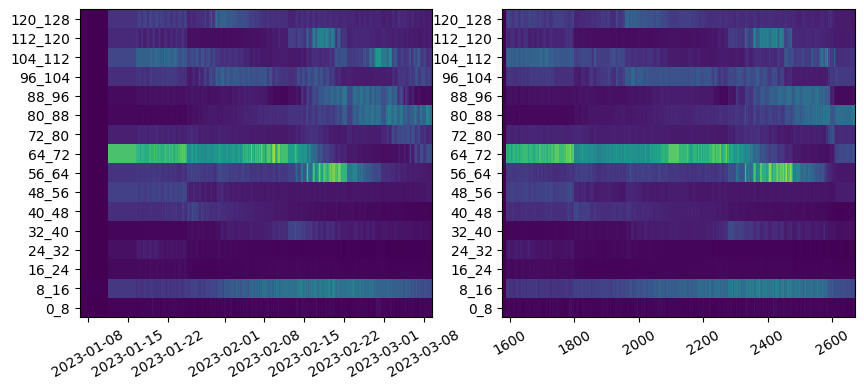

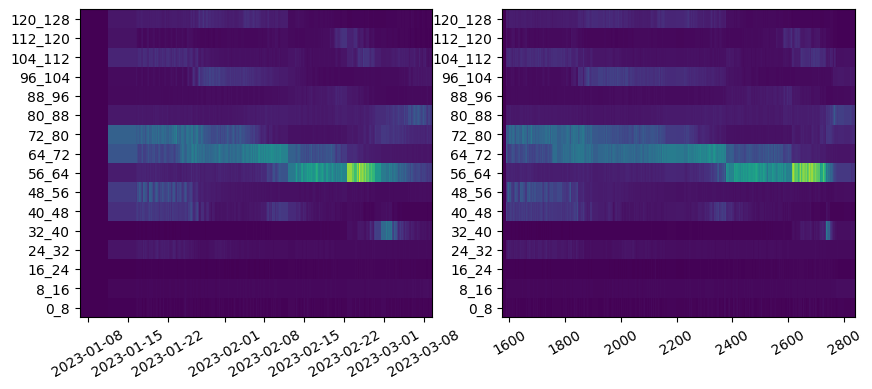

In [73]:
for ax in AXES:
    for cable in CABLES:
        temp = df.copy().loc[(df["axis"]==ax)&(df["cable"]==cable)].reset_index()
        data = temp[features]
        plt.figure(figsize=(10,4))
        plt.subplot(1,2,1)
        plt.pcolormesh(temp["sampled_at"], features, data.T)
        plt.xticks(rotation=30);
        plt.subplot(1,2,2)
        temp = temp.sort_values("tension")
        plt.pcolormesh(temp["tension"], features, data.T)
        plt.xticks(rotation=30);

In [79]:
features_low = features[0:4]
px.line(df.set_index("sampled_at")[["axis", "cable"]+features_low], facet_col="axis", facet_row="cable")

In [80]:
features_low = features[0:4]
px.line(df.set_index("tension")[["axis", "cable"]+features_low], facet_col="axis", facet_row="cable")